# Primeiros modelos de classificação

Este notebook treina os primeiros classificadores sobre a versão 1 do dataset (`dataset/v1/dataset.csv`) e avalia seu desempenho na tarefa de
**identificar a fase global do ambiente** (`normal`, `pre_desastre`, `desastre`, `pos_desastre`) a partir de
uma única tentativa de consulta a um sensor.

Etapas: leitura do dataset, análise exploratória (ver `01_analise_exploratoria.ipynb`),
tratamento de ausentes, separação entre treino e teste, treinamento e avaliação. Modelos: Árvore de Decisão,
Random Forest, Regressão Logística e KNN, mais um classificador trivial como referência. Métricas: acurácia,
precisão, revocação, F1-score e matriz de confusão, complementadas por curvas ROC e AUC.

Como análise complementar, os modelos também são comparados em quatro conjuntos de atributos (sensores; sensores +
bateria; sensores + rede; completo), antecipando a pergunta central do TCC.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier

from comum import (CLASSES, CONJUNTOS, COR_CLASSE, NOMES_CLASSES, ORDEM_PAPEIS, RESULTADOS, SEQUENCIAL, TEXTO_SEC,
                   aplicar_estilo, carregar_dados, salvar)

aplicar_estilo()
pd.set_option("display.precision", 3)
SEMENTE = 42
RESULTADOS.mkdir(exist_ok=True)
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)

pandas 3.0.6 | scikit-learn 1.9.1 | numpy 2.5.4


## 1. Dados, alvo e atributos

São usadas as 2.060 tentativas do dataset, sem as duas respostas que cruzaram fronteira de fase. **Nenhuma** linha
com falha é removida: a ausência de resposta é parte do fenômeno.

Atributos de entrada (todos observáveis por um gateway real):

| Grupo | Colunas |
|:--|:--|
| Sensores | `temperature`, `pressure` |
| Bateria | `battery` |
| Rede | `latency_ms`, `available`, `drop_rate` |

Ficam de fora, conforme `cenarios/rotulacao.md`: tempo relativo e horários, `event_name`, `event_type`,
`scenario_id`, `run_id`, identificadores de dispositivo e gateway, coordenadas, códigos CoAP, `error`,
`em_transicao` e `cruzou_fase`. Todos revelam direta ou indiretamente o roteiro da simulação.

In [2]:
dados = carregar_dados()
ATRIBUTOS = CONJUNTOS["Sensores + rede + bateria"]
y = dados["label"].astype(str)
print(f"{len(dados)} linhas; atributos completos: {ATRIBUTOS}")
y.value_counts().reindex(CLASSES).to_frame("exemplos")

2060 linhas; atributos completos: ['temperature', 'pressure', 'latency_ms', 'available', 'drop_rate', 'battery']


,exemplos
label,
normal,586
pre_desastre,538
desastre,435
pos_desastre,501


## 2. Pré-processamento

Todo o pré-processamento fica dentro de um `Pipeline` e é ajustado **somente no treino** de cada divisão:

1. `SimpleImputer(strategy="median")`: quando a consulta falha (`available = 0`), temperatura, pressão, bateria e
   latência estão ausentes e recebem a mediana do treino. O próprio `available` (e `drop_rate`) avisa o modelo de
   que aquela linha é uma falha, então a imputação não se confunde com uma leitura real.
2. `StandardScaler`: padroniza as escalas (°C, hPa, %, ms). É necessário para Regressão Logística e KNN e
   inofensivo para os modelos de árvore.

Não há reamostragem de classes; o desbalanceamento é moderado (20% a 28%) e as métricas são reportadas em média
macro.

In [3]:
MODELOS = {
    "Referência (classe majoritária)": DummyClassifier(strategy="most_frequent"),
    "Árvore de Decisão": DecisionTreeClassifier(min_samples_leaf=5, random_state=SEMENTE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=-1),
    "Regressão Logística": LogisticRegression(max_iter=5000),
    "KNN": KNeighborsClassifier(n_neighbors=15),
}


def novo_pipeline(modelo):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), clone(modelo))

Os hiperparâmetros são fixos e simples, sem otimização: `min_samples_leaf=5` evita folhas com uma única
observação na árvore, a floresta usa 300 árvores, e o KNN usa 15 vizinhos. Ajustar hiperparâmetros com uma única
execução tenderia a escolher configurações que só funcionam nela; isso fica para quando houver mais execuções.

## 3. Separação entre treino e teste

Há uma única execução de 1200 s, e consultas vizinhas no tempo são muito parecidas. Por isso, dois protocolos são
comparados:

- **Aleatório estratificado (70/30)** — divisão usual, preservando a proporção das classes. Treino e teste
  contêm instantes intercalados dos mesmos sensores, então o resultado pode ser **otimista**. Complementado
  por validação cruzada estratificada de 5 partes.
- **Por gateway** — treina com os cinco sensores de `gw01` e testa nos cinco de `gw02`, e vice-versa. Os dois
  grupos têm os mesmos papéis (falha energética, falha de rede, degradação e controle), mas são dispositivos
  diferentes, com sorteios, perdas e cargas iniciais próprios. Cada linha é prevista exatamente uma vez, por um
  modelo que não viu aquele dispositivo. É o **protocolo principal** deste notebook.

Nenhum dos dois mede generalização para **outra execução** do cenário; isso exigirá novas coletas.

In [4]:
treino_idx, teste_idx = train_test_split(dados.index, test_size=0.3, stratify=y, random_state=SEMENTE)
PROTOCOLOS = {
    "Aleatório 70/30": [(treino_idx, teste_idx)],
    "Por gateway": [
        (dados.index[dados["gateway_id"] == "gw01"], dados.index[dados["gateway_id"] == "gw02"]),
        (dados.index[dados["gateway_id"] == "gw02"], dados.index[dados["gateway_id"] == "gw01"]),
    ],
}
for nome, divisoes in PROTOCOLOS.items():
    for i, (tr, te) in enumerate(divisoes, 1):
        print(f"{nome} [{i}]: treino {len(tr)} | teste {len(te)} |",
              "classes no teste:", y[te].value_counts().reindex(CLASSES).tolist())

Aleatório 70/30 [1]: treino 1442 | teste 618 | classes no teste: [176, 161, 131, 150]
Por gateway [1]: treino 1030 | teste 1030 | classes no teste: [294, 266, 218, 252]
Por gateway [2]: treino 1030 | teste 1030 | classes no teste: [292, 272, 217, 249]


In [5]:
def prever(protocolo, atributos, modelo):
    """Treina em cada divisão do protocolo e devolve as previsões de todas as linhas de teste."""
    previsoes = []
    for tr, te in PROTOCOLOS[protocolo]:
        pipe = novo_pipeline(modelo).fit(dados.loc[tr, atributos], y[tr])
        previsoes.append(pd.Series(pipe.predict(dados.loc[te, atributos]), index=te))
    return pd.concat(previsoes).sort_index()


def metricas(y_real, y_prev):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # a referência nunca prevê algumas classes (precisão indefinida = 0)
        return {
            "acurácia": accuracy_score(y_real, y_prev),
            "precisão (macro)": precision_score(y_real, y_prev, average="macro", zero_division=0),
            "revocação (macro)": recall_score(y_real, y_prev, average="macro", zero_division=0),
            "F1 (macro)": f1_score(y_real, y_prev, average="macro", zero_division=0),
        }

## 4. Resultados com todos os atributos

In [6]:
previsoes = {}
linhas = []
for protocolo in PROTOCOLOS:
    for nome, modelo in MODELOS.items():
        prev = prever(protocolo, ATRIBUTOS, modelo)
        previsoes[(protocolo, nome)] = prev
        linhas.append({"protocolo": protocolo, "modelo": nome, **metricas(y[prev.index], prev)})
tabela = pd.DataFrame(linhas).set_index(["protocolo", "modelo"])
tabela.to_csv(RESULTADOS / "metricas_modelos.csv", float_format="%.4f")
tabela.style.format("{:.3f}").background_gradient(cmap=SEQUENCIAL, subset=["F1 (macro)"], vmin=0, vmax=1)

In [7]:
# Validação cruzada estratificada (5 partes) como verificação de estabilidade do protocolo aleatório.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
estabilidade = []
for nome, modelo in MODELOS.items():
    notas = []
    for tr, te in cv.split(dados, y):
        pipe = novo_pipeline(modelo).fit(dados.loc[tr, ATRIBUTOS], y[tr])
        notas.append(f1_score(y[te], pipe.predict(dados.loc[te, ATRIBUTOS]), average="macro"))
    estabilidade.append({"modelo": nome, "F1 macro (média)": np.mean(notas), "desvio-padrão": np.std(notas)})
pd.DataFrame(estabilidade).set_index("modelo")

,F1 macro (média),desvio-padrão
modelo,,
Referência (classe majoritária),0.111,2.939e-04
Árvore de Decisão,0.811,3.838e-03
Random Forest,0.823,1.048e-02
Regressão Logística,0.630,1.226e-02
KNN,0.616,9.498e-03


**Leitura dos resultados.** No protocolo principal (por gateway), o **Random Forest** obteve F1 macro de 0,80 e acurácia de 0,80, seguido pela **Árvore de Decisão** (0,78). **Regressão Logística** (0,63) e **KNN** (0,61) ficaram bem atrás. Todos superam com folga a referência trivial (F1 macro 0,11; acurácia 0,28), que sempre responde `normal`.

Os modelos de árvore se destacam porque a relação entre atributos e fase não é linear: a bateria cai em degraus, e o significado de uma temperatura depende de a consulta ter falhado ou não (valor imputado). Fronteiras por limiares capturam isso melhor que uma combinação linear (Regressão Logística) ou uma distância euclidiana com escalas misturadas (KNN).

Nesta execução, os dois protocolos deram resultados próximos: na divisão aleatória 70/30, Random Forest e Árvore ficaram em 0,79, e a validação cruzada de 5 partes deu 0,82 ± 0,01 (Random Forest) e 0,81 (Árvore). Ou seja, compartilhar sensores entre treino e teste inflou pouco o resultado aqui. A principal limitação de generalização continua sendo o uso de uma única execução (seção 6).

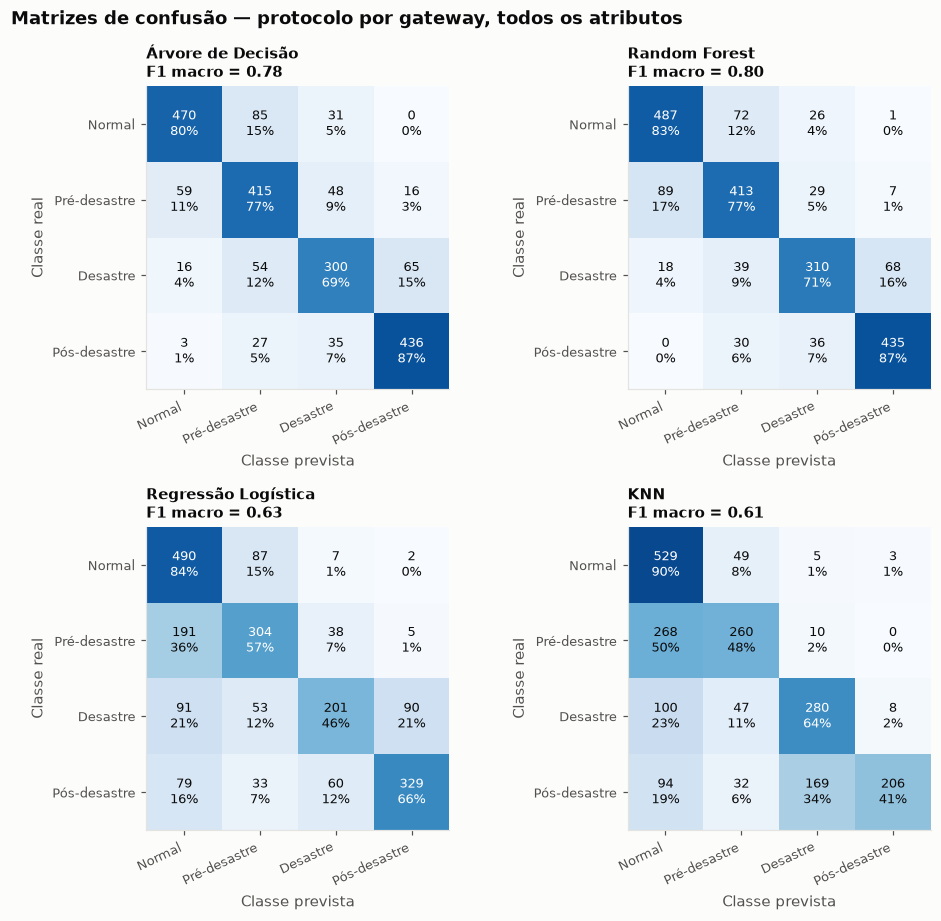

In [8]:
def matriz(ax, protocolo, modelo):
    prev = previsoes[(protocolo, modelo)]
    cm = confusion_matrix(y[prev.index], prev, labels=CLASSES)
    taxa = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(taxa, cmap=SEQUENCIAL, vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cm[i, j]}\n{100 * taxa[i, j]:.0f}%", ha="center", va="center", fontsize=8.5,
                    color="white" if taxa[i, j] > 0.55 else "#0b0b0b")
    nomes = [NOMES_CLASSES[k] for k in CLASSES]
    ax.set_xticks(range(4), nomes, rotation=25, ha="right", fontsize=8.5)
    ax.set_yticks(range(4), nomes, fontsize=8.5)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.grid(False)
    ax.set_title(f"{modelo}\nF1 macro = {f1_score(y[prev.index], prev, average='macro'):.2f}", fontsize=10)

fig, eixos = plt.subplots(2, 2, figsize=(9, 8.5))
for ax, modelo in zip(eixos.flat, ["Árvore de Decisão", "Random Forest", "Regressão Logística", "KNN"]):
    matriz(ax, "Por gateway", modelo)
fig.suptitle("Matrizes de confusão — protocolo por gateway, todos os atributos", x=0.02, ha="left",
             fontweight="bold")
fig.tight_layout()
salvar(fig, "modelos_matrizes_confusao.png")
plt.show()

Cada célula mostra a quantidade de exemplos e a porcentagem em relação à classe real (linha); a diagonal é a
revocação de cada classe.

Os erros se concentram entre **fases vizinhas**: no Random Forest, 17% do pré-desastre é confundido com normal, 12% do normal com pré-desastre e 16% do desastre com pós-desastre. Normal e pós-desastre praticamente nunca são confundidos (1 e 0 casos), pois a bateria já está muito mais baixa no fim do ciclo. A Regressão Logística e o KNN confundem com frequência o pré-desastre com o normal (36% e 50%), e o KNN atribui ao desastre 34% do pós-desastre.

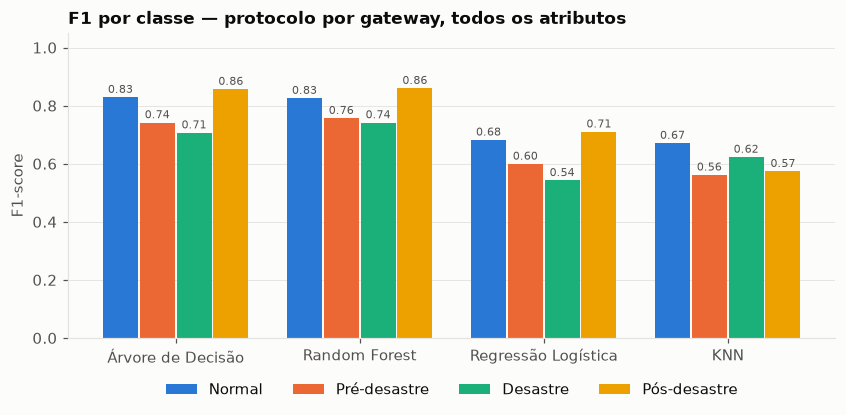

,normal,pre_desastre,desastre,pos_desastre
Referência (classe majoritária),0.443,0.000,0.000,0.000
Árvore de Decisão,0.829,0.742,0.707,0.857
Random Forest,0.825,0.756,0.742,0.860
Regressão Logística,0.682,0.599,0.543,0.710
KNN,0.671,0.562,0.623,0.574


In [9]:
f1_classes = []
for nome in MODELOS:
    prev = previsoes[("Por gateway", nome)]
    _, _, f1, _ = precision_recall_fscore_support(y[prev.index], prev, labels=CLASSES, zero_division=0)
    f1_classes.append(pd.Series(f1, index=CLASSES, name=nome))
f1_classes = pd.DataFrame(f1_classes)
f1_classes.to_csv(RESULTADOS / "f1_por_classe.csv", float_format="%.4f")

fig, ax = plt.subplots(figsize=(9, 3.6))
modelos_graf = ["Árvore de Decisão", "Random Forest", "Regressão Logística", "KNN"]
largura = 0.19
for i, classe in enumerate(CLASSES):
    pos = np.arange(len(modelos_graf)) + (i - 1.5) * (largura + 0.01)
    valores = f1_classes.loc[modelos_graf, classe]
    ax.bar(pos, valores, width=largura, color=COR_CLASSE[classe], label=NOMES_CLASSES[classe])
    for x, v in zip(pos, valores):
        ax.text(x, v + 0.015, f"{v:.2f}", ha="center", fontsize=7.5, color=TEXTO_SEC)
ax.set_xticks(range(len(modelos_graf)), modelos_graf)
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1-score")
ax.grid(axis="x", visible=False)
ax.set_title("F1 por classe — protocolo por gateway, todos os atributos")
ax.legend(ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
salvar(fig, "modelos_f1_por_classe.png")
plt.show()
f1_classes

### Matrizes de confusão no protocolo aleatório

Para comparação, as mesmas matrizes no protocolo aleatório 70/30 (618 exemplos de teste).

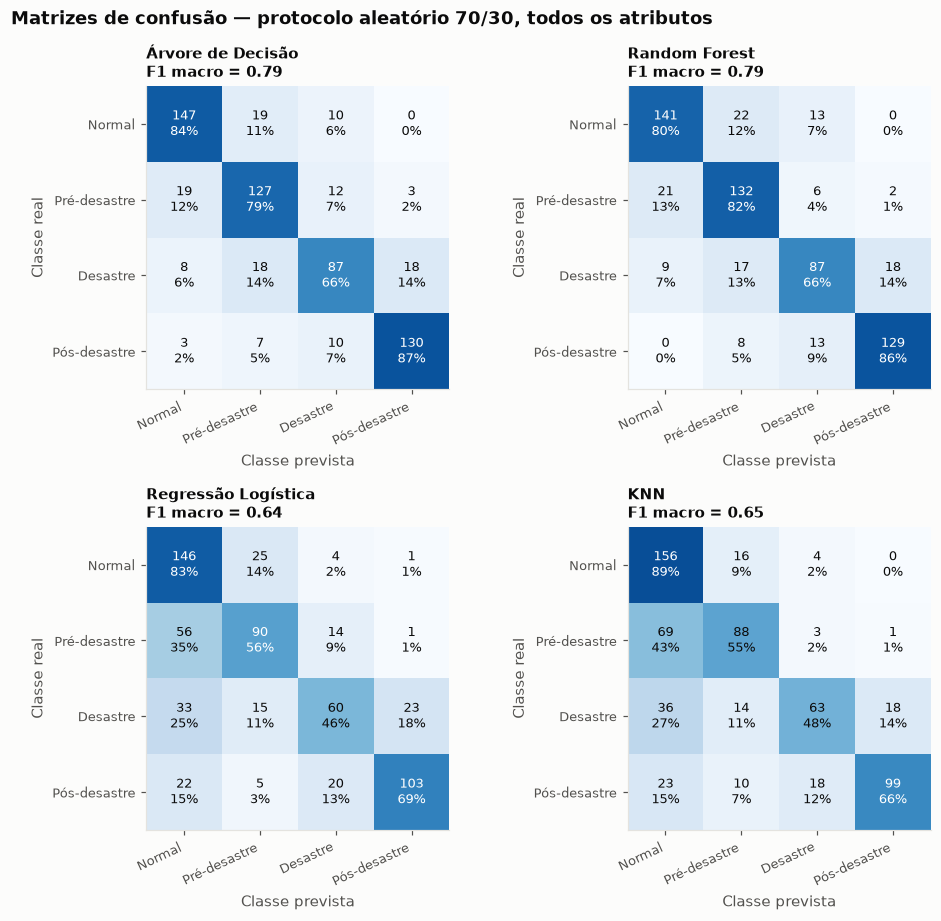

In [10]:
fig, eixos = plt.subplots(2, 2, figsize=(9, 8.5))
for ax, modelo in zip(eixos.flat, ["Árvore de Decisão", "Random Forest", "Regressão Logística", "KNN"]):
    matriz(ax, "Aleatório 70/30", modelo)
fig.suptitle("Matrizes de confusão — protocolo aleatório 70/30, todos os atributos", x=0.02, ha="left",
             fontweight="bold")
fig.tight_layout()
salvar(fig, "modelos_matrizes_confusao_aleatorio.png")
plt.show()

O padrão é o mesmo do protocolo por gateway: os erros ficam entre fases vizinhas, e normal e pós-desastre quase não se confundem. Os valores da diagonal são parecidos com os do protocolo por gateway (o Random Forest acerta 66% do desastre aqui, contra 71% por gateway), o que reforça que, nesta execução, a divisão aleatória não trouxe vantagem relevante. A Regressão Logística e o KNN continuam confundindo bastante o pré-desastre com o normal (35% e 43%).

## 5. Análise ROC

As métricas anteriores avaliam a classe escolhida. A curva ROC avalia as **probabilidades** que o modelo atribui a
cada classe, para todos os limiares de decisão possíveis. Como o problema tem quatro classes, usa-se a abordagem
**um-contra-todos** (*one-vs-rest*): para cada fase, a curva compara a taxa de verdadeiros positivos (revocação da
fase) com a taxa de falsos positivos (outras fases classificadas como ela) quando o limiar sobre a probabilidade
daquela fase varia de 1 a 0.

A **AUC** (área sob a curva) resume a curva: 1 significa que todo exemplo da fase recebe probabilidade maior que todo
exemplo das demais; 0,5 corresponde ao acaso. A **AUC macro** é a média simples das quatro AUCs.

No protocolo por gateway, as probabilidades das duas divisões são reunidas antes do cálculo, de modo que cada linha
é avaliada uma vez, por um modelo que não viu aquele dispositivo.

In [11]:
def prever_prob(protocolo, atributos, modelo):
    """Probabilidades de cada classe para todas as linhas de teste do protocolo."""
    partes = []
    for tr, te in PROTOCOLOS[protocolo]:
        pipe = novo_pipeline(modelo).fit(dados.loc[tr, atributos], y[tr])
        partes.append(pd.DataFrame(pipe.predict_proba(dados.loc[te, atributos]), index=te, columns=pipe.classes_))
    return pd.concat(partes).sort_index()[CLASSES]


probabilidades = {(protocolo, nome): prever_prob(protocolo, ATRIBUTOS, modelo)
                  for protocolo in PROTOCOLOS for nome, modelo in MODELOS.items()}

linhas_auc = []
for (protocolo, nome), prob in probabilidades.items():
    y_bin = label_binarize(y[prob.index], classes=CLASSES)
    linha = {"protocolo": protocolo, "modelo": nome}
    for i, classe in enumerate(CLASSES):
        linha[NOMES_CLASSES[classe]] = roc_auc_score(y_bin[:, i], prob[classe])
    linha["AUC macro"] = np.mean([linha[NOMES_CLASSES[c]] for c in CLASSES])  # média simples um-contra-todos
    linhas_auc.append(linha)
tabela_auc = pd.DataFrame(linhas_auc).set_index(["protocolo", "modelo"])
tabela_auc.to_csv(RESULTADOS / "auc_roc.csv", float_format="%.4f")
tabela_auc.style.format("{:.3f}").background_gradient(cmap=SEQUENCIAL, vmin=0.5, vmax=1)

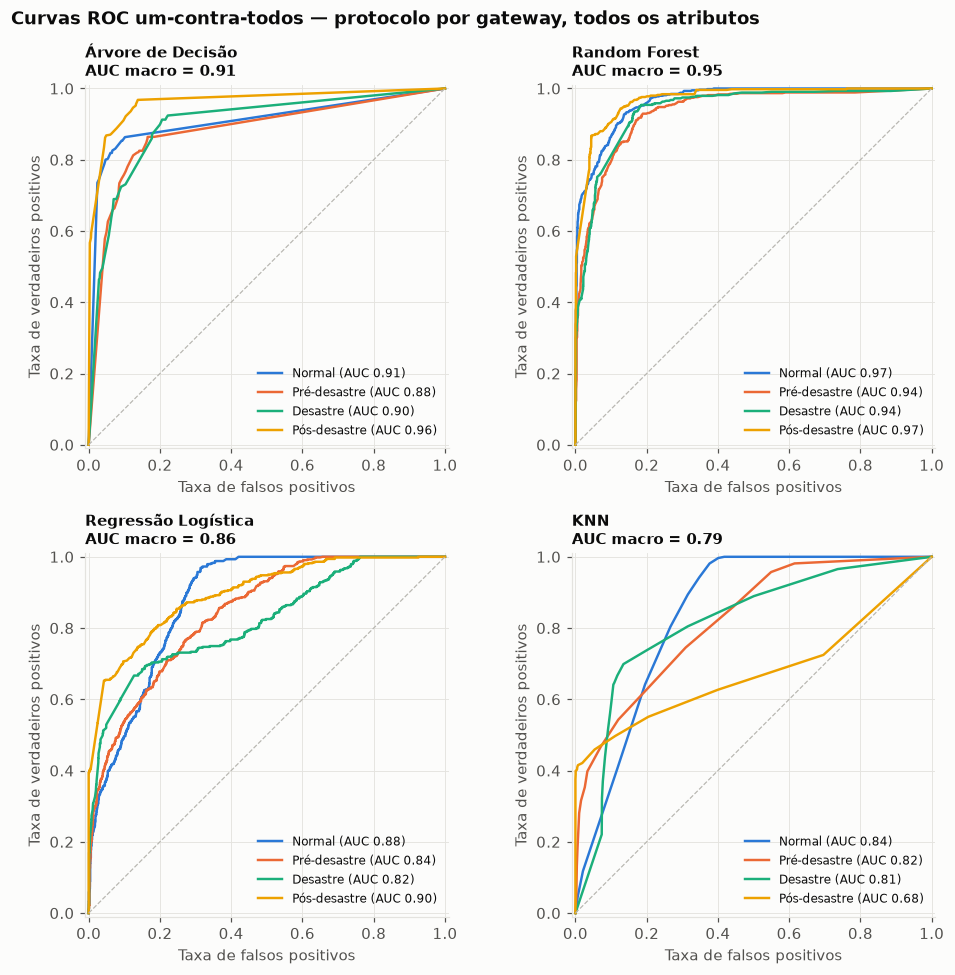

In [12]:
def curvas_roc(ax, protocolo, modelo):
    prob = probabilidades[(protocolo, modelo)]
    y_bin = label_binarize(y[prob.index], classes=CLASSES)
    for i, classe in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], prob[classe])
        auc = roc_auc_score(y_bin[:, i], prob[classe])
        ax.plot(fpr, tpr, color=COR_CLASSE[classe], lw=1.6, label=f"{NOMES_CLASSES[classe]} (AUC {auc:.2f})")
    ax.plot([0, 1], [0, 1], color="#b8b7b1", lw=0.8, ls="--")
    ax.set_xlim(-0.01, 1.01)
    ax.set_ylim(-0.01, 1.01)
    ax.set_aspect("equal")
    ax.set_xlabel("Taxa de falsos positivos")
    ax.set_ylabel("Taxa de verdadeiros positivos")
    ax.set_title(f"{modelo}\nAUC macro = {tabela_auc.loc[(protocolo, modelo), 'AUC macro']:.2f}", fontsize=10)
    ax.legend(loc="lower right", fontsize=8)

fig, eixos = plt.subplots(2, 2, figsize=(9, 9))
for ax, modelo in zip(eixos.flat, ["Árvore de Decisão", "Random Forest", "Regressão Logística", "KNN"]):
    curvas_roc(ax, "Por gateway", modelo)
fig.suptitle("Curvas ROC um-contra-todos — protocolo por gateway, todos os atributos", x=0.02, ha="left",
             fontweight="bold")
fig.tight_layout()
salvar(fig, "modelos_roc.png")
plt.show()

**Leitura das curvas ROC.**

- **Ordem dos modelos.** É a mesma do F1: Random Forest (AUC macro 0,95), Árvore de Decisão (0,91), Regressão Logística (0,86) e KNN (0,79). A referência fica em 0,50, o acaso. No protocolo aleatório, os valores são próximos (Random Forest 0,96; Árvore 0,93).
- **AUC acima do F1.** A AUC mede se a probabilidade da classe certa costuma ser *maior* que a dos exemplos de outras classes, para qualquer limiar. Já o F1 depende apenas da classe de maior probabilidade. Uma consulta do pré-desastre com 0,45 para `pre_desastre` e 0,50 para `normal` conta como erro na matriz, mas ainda fica bem posicionada na curva do pré-desastre. As probabilidades, portanto, carregam mais informação que a decisão final. Isso permitiria ajustar limiares — por exemplo, para aumentar a revocação do desastre num sistema de alerta, aceitando mais falsos alarmes.
- **Por classe.** O pós-desastre é a classe mais fácil (AUC 0,97 no Random Forest), e pré-desastre e desastre as mais difíceis (0,94), o que coincide com as matrizes de confusão. Na Árvore, o pré-desastre é a mais fraca (0,88).
- **Formato das curvas.** A Árvore de Decisão produz poucas probabilidades distintas (uma por folha), e o KNN só produz frações de 15 vizinhos. Por isso as curvas desses modelos têm poucos degraus e trechos retos. No KNN, a curva do pós-desastre (AUC 0,68) é a mais fraca, coerente com a confusão de 34% entre pós-desastre e desastre vista na matriz.

In [13]:
# AUC macro por conjunto de atributos (protocolo por gateway), para comparar com o F1 macro da seção 6.
auc_conjuntos = []
for nome_conj, atributos in {**CONJUNTOS, "Apenas bateria (diagnóstico)": ["battery"]}.items():
    for nome in ["Árvore de Decisão", "Random Forest", "Regressão Logística", "KNN"]:
        prob = prever_prob("Por gateway", atributos, MODELOS[nome])
        y_bin = label_binarize(y[prob.index], classes=CLASSES)
        auc_conjuntos.append({"conjunto": nome_conj, "modelo": nome,
                              "AUC macro": np.mean([roc_auc_score(y_bin[:, i], prob[c]) for i, c in enumerate(CLASSES)])})
auc_conjuntos = pd.DataFrame(auc_conjuntos).pivot(index="conjunto", columns="modelo", values="AUC macro")
auc_conjuntos = auc_conjuntos.reindex(index=[*CONJUNTOS, "Apenas bateria (diagnóstico)"],
                                      columns=["Árvore de Decisão", "Random Forest", "Regressão Logística", "KNN"])
auc_conjuntos.to_csv(RESULTADOS / "auc_conjuntos_atributos.csv", float_format="%.4f")
auc_conjuntos.round(3)

modelo,Árvore de Decisão,Random Forest,Regressão Logística,KNN
conjunto,,,,
Sensores,0.674,0.703,0.636,0.558
Sensores + bateria,0.905,0.925,0.772,0.671
Sensores + rede,0.734,0.785,0.778,0.723
Sensores + rede + bateria,0.913,0.953,0.859,0.788
Apenas bateria (diagnóstico),0.907,0.916,0.727,0.820


A AUC por conjunto de atributos repete a conclusão da seção seguinte: só com sensores, a AUC macro fica entre 0,56 e 0,70; com rede, entre 0,72 e 0,79; com bateria, os modelos de árvore passam de 0,90; e o conjunto completo chega a 0,95 no Random Forest. A bateria sozinha já atinge 0,91 a 0,92 nos modelos de árvore — mais uma indicação do efeito relógio discutido a seguir.

## 6. Comparação entre conjuntos de atributos

Os mesmos modelos são treinados com subconjuntos dos atributos, sempre no protocolo por gateway. Como diagnóstico,
inclui-se também um modelo que vê **apenas a bateria**.

In [14]:
conjuntos = {**CONJUNTOS, "Apenas bateria (diagnóstico)": ["battery"]}
comparacao = []
for nome_conj, atributos in conjuntos.items():
    for nome, modelo in MODELOS.items():
        if nome.startswith("Referência"):
            continue
        for protocolo in PROTOCOLOS:
            prev = prever(protocolo, atributos, modelo)
            comparacao.append({"conjunto": nome_conj, "modelo": nome, "protocolo": protocolo,
                               "F1 (macro)": f1_score(y[prev.index], prev, average="macro"),
                               "acurácia": accuracy_score(y[prev.index], prev)})
comparacao = pd.DataFrame(comparacao)
comparacao.to_csv(RESULTADOS / "conjuntos_atributos.csv", index=False, float_format="%.4f")
ordem_modelos = [m for m in MODELOS if not m.startswith("Referência")]
for protocolo in PROTOCOLOS:
    print(f"F1 macro — {protocolo}")
    display(comparacao[comparacao["protocolo"] == protocolo]
            .pivot(index="conjunto", columns="modelo", values="F1 (macro)")
            .reindex(index=list(conjuntos), columns=ordem_modelos).round(3))

F1 macro — Aleatório 70/30


modelo,Árvore de Decisão,Random Forest,Regressão Logística,KNN
conjunto,,,,
Sensores,0.389,0.410,0.328,0.416
Sensores + bateria,0.728,0.724,0.492,0.583
Sensores + rede,0.493,0.556,0.551,0.550
Sensores + rede + bateria,0.789,0.787,0.637,0.650
Apenas bateria (diagnóstico),0.698,0.660,0.388,0.696


F1 macro — Por gateway


modelo,Árvore de Decisão,Random Forest,Regressão Logística,KNN
conjunto,,,,
Sensores,0.389,0.423,0.343,0.344
Sensores + bateria,0.723,0.720,0.493,0.495
Sensores + rede,0.512,0.543,0.562,0.493
Sensores + rede + bateria,0.783,0.796,0.633,0.607
Apenas bateria (diagnóstico),0.709,0.711,0.394,0.659


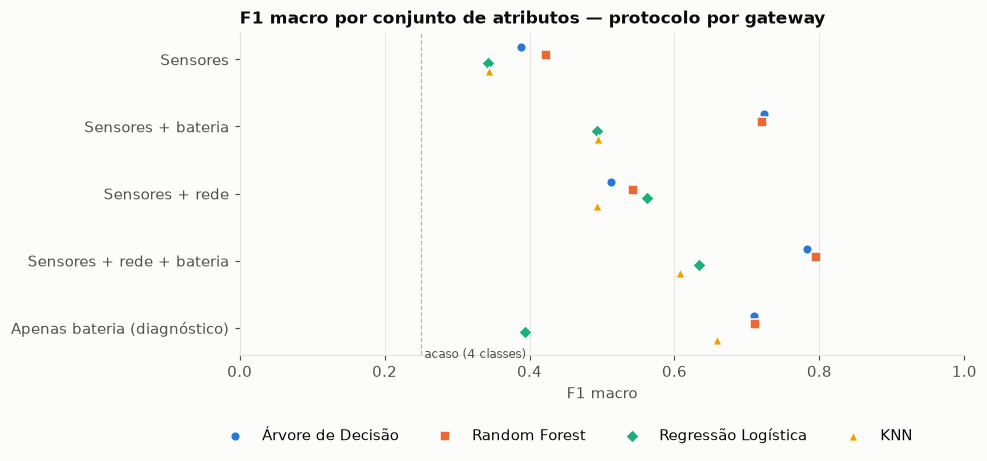

In [15]:
gw = comparacao[comparacao["protocolo"] == "Por gateway"].pivot(index="conjunto", columns="modelo", values="F1 (macro)")
gw = gw.reindex(list(conjuntos))[modelos_graf]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
marcadores = ["o", "s", "D", "^"]
for i, (modelo, cor) in enumerate(zip(modelos_graf, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])):
    ax.scatter(gw[modelo], np.arange(len(gw)) + (i - 1.5) * 0.12, color=cor, s=40, marker=marcadores[i],
               label=modelo, zorder=3, edgecolor="#fcfcfb", linewidth=1)
ax.set_yticks(range(len(gw)), gw.index)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.axvline(0.25, color="#b8b7b1", lw=0.8, ls="--")
ax.text(0.255, len(gw) - 0.55, "acaso (4 classes)", fontsize=8, color=TEXTO_SEC)
ax.set_xlabel("F1 macro")
ax.grid(axis="y", visible=False)
ax.set_title("F1 macro por conjunto de atributos — protocolo por gateway")
ax.legend(ncols=4, loc="upper center", bbox_to_anchor=(0.45, -0.18))
salvar(fig, "modelos_conjuntos_atributos.png")
plt.show()

**O que cada grupo de atributos acrescenta** (protocolo por gateway):

- **Apenas sensores**: F1 macro entre 0,34 e 0,42, pouco acima do acaso (0,25). A pressão não varia entre fases, e a temperatura se sobrepõe entre pré-desastre, desastre e pós-desastre; além disso, os controles têm leituras normais em todas as fases.
- **Sensores + rede**: 0,49 a 0,56. Latência, falhas e disponibilidade acrescentam cerca de 0,12 ao Random Forest em relação aos sensores.
- **Sensores + bateria**: 0,72 nos modelos de árvore.
- **Completo**: 0,78 a 0,80 nos modelos de árvore, o melhor resultado.
- **Apenas bateria**: 0,71 nos modelos de árvore — quase o mesmo que sensores + bateria e menos de 0,10 abaixo do conjunto completo.

Os resultados apoiam a hipótese de que informações da infraestrutura melhoram a classificação. Porém, a maior parte do ganho vem da **bateria usada como relógio**: em uma única execução, a carga decresce monotonicamente e indica em que ponto do ciclo a consulta foi feita. Esse efeito é um artefato do experimento com uma só execução e carga inicial semelhante; não deve ser interpretado como capacidade de detectar desastres. O ganho da rede (sensores → sensores + rede) é mais plausível de se manter em outras execuções, porque reflete diretamente a degradação programada.

## 7. Importância dos atributos (Random Forest)

A importância por permutação mede quanto o F1 macro cai quando os valores de um atributo são embaralhados no
conjunto de teste. É calculada nas duas divisões do protocolo por gateway e reportada como média.

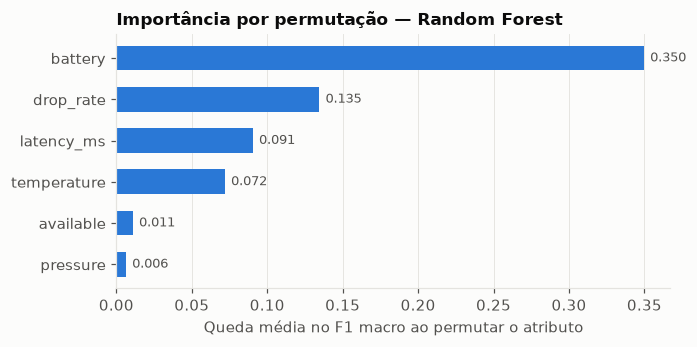

In [16]:
importancias = []
for tr, te in PROTOCOLOS["Por gateway"]:
    pipe = novo_pipeline(MODELOS["Random Forest"]).fit(dados.loc[tr, ATRIBUTOS], y[tr])
    r = permutation_importance(pipe, dados.loc[te, ATRIBUTOS], y[te], scoring="f1_macro", n_repeats=20,
                               random_state=SEMENTE, n_jobs=-1)
    importancias.append(pd.Series(r.importances_mean, index=ATRIBUTOS))
importancia = pd.concat(importancias, axis=1).mean(axis=1).sort_values()
importancia.to_frame("queda média no F1 macro").to_csv(RESULTADOS / "importancia_atributos.csv", float_format="%.4f")

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh(importancia.index, importancia.values, color="#2a78d6", height=0.6)
for i, v in enumerate(importancia.values):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8.5, color=TEXTO_SEC)
ax.set_xlabel("Queda média no F1 macro ao permutar o atributo")
ax.grid(axis="y", visible=False)
ax.set_title("Importância por permutação — Random Forest")
salvar(fig, "modelos_importancia.png")
plt.show()

A permutação confirma a dependência da bateria: embaralhá-la reduz o F1 macro em 0,35, mais que o dobro de qualquer outro atributo. Em seguida vêm `drop_rate` (0,14), `latency_ms` (0,09) e `temperature` (0,07). A pressão tem importância praticamente nula, como esperado. A importância baixa de `available` (0,01) não significa que a falha seja irrelevante: a mesma informação já está em `drop_rate` e nos valores imputados, e a permutação de um atributo redundante quase não altera o resultado.

## 8. Análise dos erros

As previsões do Random Forest no protocolo por gateway são cruzadas com metadados de auditoria que **não** foram
usados no treino: papel do dispositivo, disponibilidade e período de transição.

In [17]:
prev_rf = previsoes[("Por gateway", "Random Forest")]
analise = dados.assign(previsto=prev_rf, acerto=(prev_rf == y))

por_papel = (analise.groupby(["papel", "label"], observed=True)["acerto"].mean().unstack()
             .reindex(index=ORDEM_PAPEIS, columns=CLASSES))
por_papel["geral"] = analise.groupby("papel")["acerto"].mean().reindex(ORDEM_PAPEIS)
por_papel.to_csv(RESULTADOS / "acertos_por_papel.csv", float_format="%.4f")
por_papel.style.format("{:.0%}").background_gradient(cmap=SEQUENCIAL, vmin=0, vmax=1)

label,normal,pre_desastre,desastre,pos_desastre,geral
papel,,,,,
Falha energética,100%,88%,42%,100%,84%
Falha de rede,89%,74%,85%,78%,82%
Degradação,70%,74%,89%,82%,78%
Controle,86%,74%,67%,87%,78%


In [18]:
resumo = pd.concat({
    "disponível": analise.groupby(["available", "label"], observed=True)["acerto"].mean().unstack(),
    "em transição": analise.groupby(["em_transicao", "label"], observed=True)["acerto"].mean().unstack(),
}).reindex(columns=CLASSES)
resumo.style.format("{:.0%}", na_rep="—")

In [19]:
# Confusões mais frequentes.
erros = analise[~analise["acerto"]]
(erros.groupby(["label", "previsto"], observed=True).size().sort_values(ascending=False)
 .head(8).to_frame("erros"))

erros
label        previsto           
pre_desastre normal           89
normal       pre_desastre     72
desastre     pos_desastre     68
             pre_desastre     39
pos_desastre desastre         36
             pre_desastre     30
pre_desastre desastre         29
normal       desastre         26

**Principais padrões de erro (Random Forest, protocolo por gateway):**

- **Controles (`d05`)**: 74% de acerto no pré-desastre e 67% no desastre, embora suas leituras sejam idênticas às do estado normal. O único sinal que os distingue no tempo é a bateria, que cai lentamente (de cerca de 97% para 94%). Esses acertos são mais uma evidência do efeito relógio.
- **Falha energética (`d01`) no desastre**: apenas 42% de acerto. Depois do esgotamento, o sensor só responde `5.03`; uma falha no fim do desastre é indistinguível de uma falha no pós-desastre. Das 68 previsões de desastre como pós-desastre, 56 vêm do `d01`, todas tentativas sem medições.
- **Tentativas sem medições**: 65% de acerto, contra 83% nas respostas válidas.
- **Transições**: no início do desastre (600–630 s), o acerto cai para 47%, contra 74% no restante da fase, porque os parâmetros ainda estão mudando.
- **Pré-desastre previsto como normal** (89 casos): a faixa de temperatura do pré-desastre contém a faixa normal, e a latência só muda a partir de ~390 s.

Parte desses erros é inevitável em uma classificação **por linha**: uma única consulta a um controle ou a um sensor esgotado não contém informação sobre a fase. Agregar consultas de vários dispositivos ou usar janelas temporais deve reduzir esses erros.

## 9. Conclusões preliminares

1. Com todos os atributos e o protocolo por gateway, os modelos de árvore identificam as quatro fases com F1 macro de cerca de 0,80 (Random Forest 0,80; Árvore 0,78), muito acima da referência (0,11). Regressão Logística e KNN ficam entre 0,61 e 0,63. Na análise ROC, a AUC macro segue a mesma ordem (Random Forest 0,95; Árvore 0,91; Regressão Logística 0,86; KNN 0,79).
2. Apenas com sensores, o desempenho fica pouco acima do acaso. Rede e bateria aumentam muito o desempenho.
3. O resultado depende fortemente da bateria, que nesta execução funciona como um relógio. Portanto, **o desempenho atual é otimista** e não demonstra generalização.
4. Os erros restantes vêm de fases vizinhas, transições, controles e sensores esgotados, que uma consulta isolada não consegue diferenciar.

**Limitações:** uma única execução, papéis idênticos nos dois gateways, hiperparâmetros fixos e cenário sintético sem calibração física.

**Próximos passos:**

- gerar várias execuções completas, com cargas iniciais, sementes e dispositivos afetados diferentes, e separar **execuções inteiras** entre treino e teste;
- testar a bateria como **variação** (taxa de descarga entre consultas) em vez de nível absoluto, ou avaliá-la separadamente, para reduzir o efeito relógio;
- incluir atributos de janela temporal por sensor e agregados por gateway;
- ajustar hiperparâmetros por validação cruzada agrupada por execução.